# YOLO26-M (Ultralytics) — Training

Fine-tunes the COCO-pretrained `yolo26m.pt` on Construction-PPE. The test-set evaluation is in
[`yolo26m_eval.ipynb`](yolo26m_eval.ipynb).

| Setting | Value |
|---|---|
| Input size | 640×640 |
| Optimizer, LR schedule, loss | Ultralytics defaults for this model (`optimizer="auto"`) |
| Batch size | 16 |
| Epochs | 10 (scratch run; training runs use up to `MAX_EPOCHS` = 200) |
| Early stopping | patience 15 on validation mAP@50-95 |
| Checkpoint | best validation fitness → `models/yolo26m/weights/best.pt` |

> **Scratch run.** `EPOCHS` is set to **10** in the hyperparameter cell so the notebook runs end to end quickly; use
> a higher value such as `MAX_EPOCHS` (200) for training runs.

**Data augmentation** uses the same family (steps, ranges and probabilities) in all four models
(`ppe_detection_evaluation.dataset.augmentations`). The Ultralytics models apply it with Ultralytics' own pipeline,
configured through `ULTRALYTICS_AUGMENTATION`.

| # | Augmentation | Parameters | p |
|---|---|---|---|
| A1 | Horizontal flip | — | 0.5 |
| A2 | Scale + translate | scale 0.75–1.25, translate ±10 %, gray fill 114 | 1.0 |
| A3 | Brightness jitter | brightness factor 0.6–1.4 | 1.0 |

Every image is first resized to 640×640. Boxes keeping less than 40 % of their area, or narrower than 3 px, are dropped.
Validation and test images are only resized.

`ULTRALYTICS_AUGMENTATION` (`ultralytics_adapter.py`) sets Ultralytics' arguments to the table above and turns off
mosaic and HSV saturation/hue jitter. Protocol differences from the torchvision models, reported as such: Ultralytics
resizes with its own logic, filters cropped boxes with its own thresholds, and applies blur / median blur / grayscale /
CLAHE at p=0.01 each.

In [ ]:
import csv

%matplotlib inline
import matplotlib.pyplot as plt
from ultralytics import YOLO

from ppe_detection_evaluation.dataset.core import check_dataset, class_box_counts, download_dataset
from ppe_detection_evaluation.dataset.ultralytics_adapter import ULTRALYTICS_AUGMENTATION, write_ultralytics_yaml
from ppe_detection_evaluation.experiment import DATA_ROOT, IMAGE_SIZE, MAX_EPOCHS, MODELS_DIR, PRETRAINED_DIR, SEED
from ppe_detection_evaluation.utilities.visualize import plot_examples

## Hyperparameters

Everything tunable for this model is set in the next cell. `SEED`, `IMAGE_SIZE` and `MAX_EPOCHS` are shared by all four
notebooks (`experiment.py`): the seed makes runs reproducible. Epochs, early stopping, batch size and optimizer settings
are chosen per model.

In [2]:
EPOCHS = 10  # set higher for training runs, such as MAX_EPOCHS
PATIENCE = 15  # epochs without a validation mAP@50-95 improvement
BATCH_SIZE = 16   # Ultralytics' default; batch=-1 lets Ultralytics pick the largest that fits
# Optimizer, LR schedule and loss weights stay at Ultralytics' defaults (optimizer="auto").

In [3]:
# SEED, DATA_ROOT and the model folders come from experiment.py and are shared by all four notebooks.
PROJECT_DIR = MODELS_DIR  # the run lands in models/<RUN_NAME>/ (weights/, curves, results.csv)
RUN_NAME = "yolo26m"
print(f"Epochs: {EPOCHS} | Batch: {BATCH_SIZE} | Image size: {IMAGE_SIZE}")

Epochs: 10 | Batch: 16 | Image size: 640


## 1. Dataset

[Ultralytics Construction-PPE](https://docs.ultralytics.com/datasets/detect/construction-ppe/): 7 of its 11 classes are
kept: `person` and the present/absent pairs helmet / no_helmet, vest / no_vest and gloves / no_gloves; boxes of the other classes are
dropped when the labels are written. `download_dataset` is a no-op once
`data/construction-ppe` exists, so all four notebooks share one copy.

In [ ]:
download_dataset(DATA_ROOT)
splits = check_dataset(DATA_ROOT)  # raises if the class order differs from DEFAULT_CLASS_NAMES

counts = {split: class_box_counts(DATA_ROOT, split) for split in splits}
print(f"{'Boxes':<10}" + "".join(f"{split.capitalize():>8}" for split in splits))
for name in counts["train"]:
    print(f"{name:<10}" + "".join(f"{counts[split][name]:>8}" for split in splits))
print("-" * (10 + 8 * len(splits)))
print(f"{'Images':<10}" + "".join(f"{n:>8}" for n in splits.values()))

# Ultralytics resolves relative paths in data.yaml against the CWD, so write one with absolute paths.
data_yaml = write_ultralytics_yaml(DATA_ROOT)

## 2. Model

COCO-pretrained YOLO26-M. When training starts, Ultralytics rebuilds the model with the dataset's 7 classes and
copies every pretrained tensor whose name and shape match. Only the last 1×1 conv of each of the three class branches
(and of their copies in the NMS-free one-to-one branch) starts fresh; the backbone, neck and box branch keep their COCO
weights.

In [8]:
model = YOLO(PRETRAINED_DIR / "yolo26m.pt")  # COCO weights, downloaded here on first use
model.info()

YOLO26m summary: 280 layers, 21,896,248 parameters, 0 gradients, 75.6 GFLOPs


(280, 21896248, 0, 75.6350976)

## 3. Training

After training starts, open `train_batch0.jpg` in the run directory: it must show single images with mild scale,
brightness changes, and **no** mosaic collages, colour shifts or grayscale frames.

In [ ]:
model.train(
    data=str(data_yaml),
    epochs=EPOCHS,
    patience=PATIENCE,
    batch=BATCH_SIZE,
    imgsz=IMAGE_SIZE,
    seed=SEED,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,
    **ULTRALYTICS_AUGMENTATION,
)

save_dir = model.trainer.save_dir
print(f"\nResults saved to: {save_dir}")

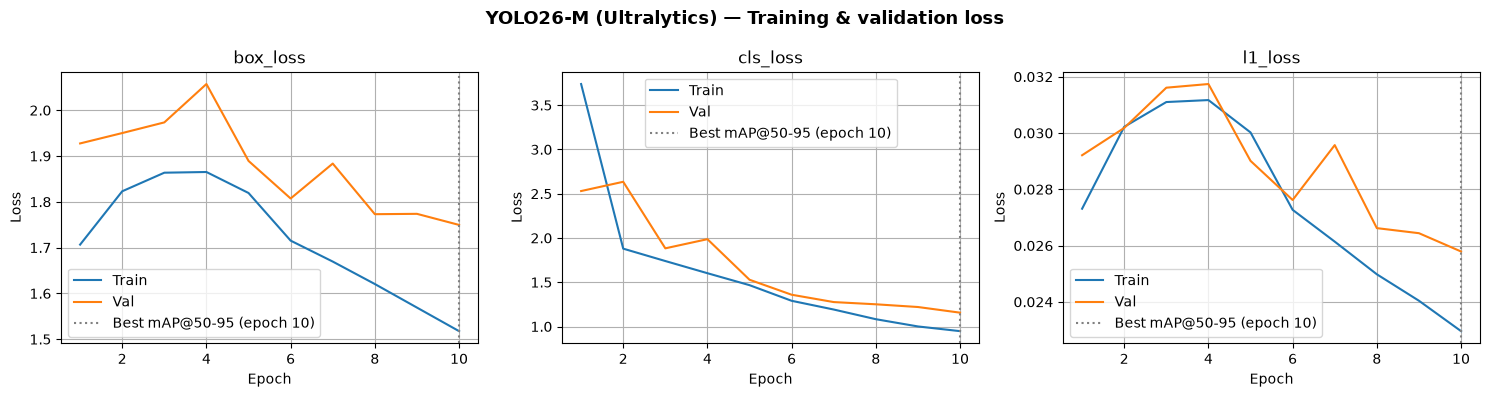

In [10]:
with open(save_dir / "results.csv") as f:
    rows = list(csv.DictReader(f))
history = {key.strip(): [float(row[key]) for row in rows] for key in rows[0]}
epochs_x = history["epoch"]
best_epoch = epochs_x[max(range(len(rows)), key=lambda i: history["metrics/mAP50-95(B)"][i])]

# Loss terms differ per model (e.g. box/cls/l1 for YOLO26, giou/cls/l1 for RT-DETR), so read them from the CSV.
losses = [key.removeprefix("train/") for key in history if key.startswith("train/")]
fig, axes = plt.subplots(1, len(losses), figsize=(5 * len(losses), 4))
for ax, loss in zip(axes, losses):
    ax.plot(epochs_x, history[f"train/{loss}"], label="Train")
    ax.plot(epochs_x, history[f"val/{loss}"], label="Val")
    ax.axvline(best_epoch, color="grey", linestyle=":", lw=1.5, label=f"Best mAP@50-95 (epoch {best_epoch:.0f})")
    ax.set(xlabel="Epoch", ylabel="Loss", title=loss)
    ax.legend()
    ax.grid(True)
plt.suptitle("YOLO26-M (Ultralytics) — Training & validation loss", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(save_dir / "loss_curves.png", dpi=150)
plt.show()

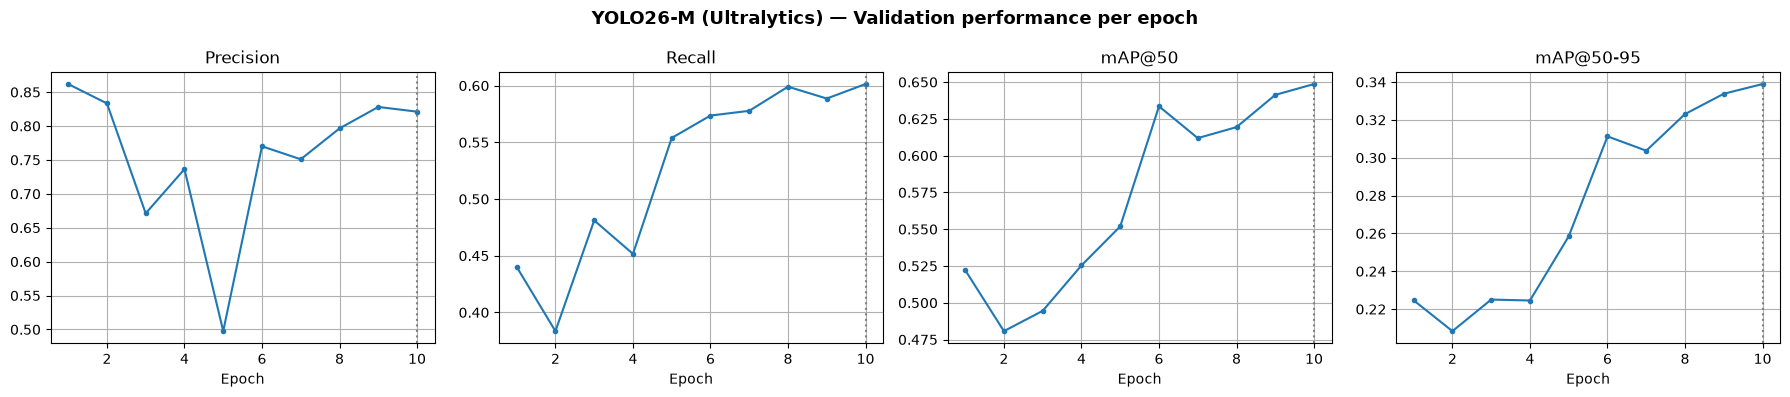

In [11]:
metrics = [
    ("metrics/precision(B)", "Precision"),
    ("metrics/recall(B)", "Recall"),
    ("metrics/mAP50(B)", "mAP@50"),
    ("metrics/mAP50-95(B)", "mAP@50-95"),
]
fig, axes = plt.subplots(1, len(metrics), figsize=(18, 4))
for ax, (key, label) in zip(axes, metrics):
    ax.plot(epochs_x, history[key], marker="o", markersize=3)
    ax.axvline(best_epoch, color="grey", linestyle=":", lw=1.5)
    ax.set(xlabel="Epoch", title=label)
    ax.grid(True)
plt.suptitle("YOLO26-M (Ultralytics) — Validation performance per epoch", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(save_dir / "val_metrics.png", dpi=150)
plt.show()

Next: evaluate `models/yolo26m/weights/best.pt` on the test split with [`yolo26m_eval.ipynb`](yolo26m_eval.ipynb).